# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random
import os

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)
from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

In [2]:
runs_to_download = []
# Sparsity time points
runs_to_download.extend(
    mlflow.search_runs(filter_string=f"attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction'",
                        experiment_ids=['9'], output_format='list'))
# All time points (from original run)
runs_to_download.extend(mlflow.search_runs(
    filter_string="attributes.status = 'FINISHED' and tags.run_type = 'model_training_and_prediction' and tags.mlflow.parentRunId = 'f02bf732b2ba4817b254bd5174f1549b'",
      experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-08-07 09:48:40,435 - INFO - Downloading artifacts for run fef5b5fe33a94235b770dace42b530e9


30


2026-08-07 09:48:47,720 - INFO - Downloading artifacts for run dfeae4e445d148188dc2fc9192284d58
2026-08-07 09:48:50,314 - INFO - Downloading artifacts for run 667eb699a97d4cafbee808c259d48264
2026-08-07 09:48:51,941 - INFO - Downloading artifacts for run 5cc99b668c9b4f4e917af7421bb0fc3d
2026-08-07 09:48:53,596 - INFO - Downloading artifacts for run 3151b4964dd742db93a2fdf4d26ad9a8
2026-08-07 09:48:55,245 - INFO - Downloading artifacts for run 2ede31ce77dd438b8b560289a1f070fa
2026-08-07 09:48:56,938 - INFO - Downloading artifacts for run 601bbb5d09924cab9ce3d2ceeb34b948
2026-08-07 09:48:58,589 - INFO - Downloading artifacts for run f054227f1a1c4261850f9ba8ba91da58
2026-08-07 09:49:00,274 - INFO - Downloading artifacts for run c1c66d50752f45f29bcf93edb7633ada
2026-08-07 09:49:01,980 - INFO - Downloading artifacts for run d352eb67ef47433bbff64f73589222cd
2026-08-07 09:49:03,653 - INFO - Downloading artifacts for run a5ee18247d2140b5b1619849e34eb87f
2026-08-07 09:49:05,274 - INFO - Downloa

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.134606,0.134606,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.741639,0.741639,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.124709,0.124709,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.955923,0.955923,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.318532,0.318532,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b


In [3]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None),
        'nr_timepoints': run.data.params.get('n_timepoints_training', 21)
        })
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name,modelled_genes,nr_timepoints
0,fef5b5fe33a94235b770dace42b530e9,MLP,None,16
1,dfeae4e445d148188dc2fc9192284d58,HybridModel,"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Nod...",16
2,667eb699a97d4cafbee808c259d48264,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",16
3,5cc99b668c9b4f4e917af7421bb0fc3d,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",16
4,3151b4964dd742db93a2fdf4d26ad9a8,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",16
5,2ede31ce77dd438b8b560289a1f070fa,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",16
6,601bbb5d09924cab9ce3d2ceeb34b948,HybridModel,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",9
7,f054227f1a1c4261850f9ba8ba91da58,HybridModel,"['Node_30', 'Node_39', 'Node_10', 'Node_22', '...",9
8,c1c66d50752f45f29bcf93edb7633ada,HybridModel,"['Node_13', 'Node_0', 'Node_24', 'Node_5', 'No...",9
9,d352eb67ef47433bbff64f73589222cd,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",9


In [5]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

In [8]:
raw_predictions_df['nr_timepoints'].value_counts()

nr_timepoints
21    630000
16    555000
11    480000
9     450000
6     405000
Name: count, dtype: int64

In [10]:
raw_predictions_df['parent_run_id'].unique()

array(['f02bf732b2ba4817b254bd5174f1549b'], dtype=object)

Add noiseless expression values

In [9]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-08-07 09:51:05,550 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-08-07 09:51:05,554 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-08-07 09:51:05,624 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-08-07 09:51:05,628 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-08-07 09:51:05,648 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-08-07 09:51:05,672 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-08-07 09:51:05,699 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-08-07 09:51:05,716 - WARNING - Connection p

In [11]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes,nr_timepoints
0,Node_0,0.0,0.134606,0.134606,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16
1,Node_1,0.0,0.741639,0.741639,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16
2,Node_2,0.0,0.124709,0.124709,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16
3,Node_3,0.0,0.955923,0.955923,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16
4,Node_4,0.0,0.318532,0.318532,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16


In [12]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.022225,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.557310,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.080057,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.702816,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.057769,KO: Node_0. Env: None,f02bf732b2ba4817b254bd5174f1549b


Merging

In [13]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

In [14]:
outcome

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,nr_timepoints,ground_truth_from_simulation,run_id_from_simulation
0,Node_0,0.0,0.134606,0.134606,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16,0.022225,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.741639,0.741639,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16,0.557310,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.124709,0.124709,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16,0.080057,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.955923,0.955923,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16,0.702816,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.318532,0.318532,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,f02bf732b2ba4817b254bd5174f1549b,MLP,None,16,0.057769,f02bf732b2ba4817b254bd5174f1549b
...,...,...,...,...,...,...,...,...,...,...,...,...
2519995,Node_45,1.0,1.003480,0.821199,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,21,0.925542,f02bf732b2ba4817b254bd5174f1549b
2519996,Node_46,1.0,0.394155,0.294828,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,21,0.321352,f02bf732b2ba4817b254bd5174f1549b
2519997,Node_47,1.0,0.190476,0.136453,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,21,0.138196,f02bf732b2ba4817b254bd5174f1549b
2519998,Node_48,1.0,0.806056,0.756552,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,f02bf732b2ba4817b254bd5174f1549b,MLP,None,21,0.833160,f02bf732b2ba4817b254bd5174f1549b


<Axes: xlabel='ground_truth_from_simulation', ylabel='ground_truth_from_pred_df'>

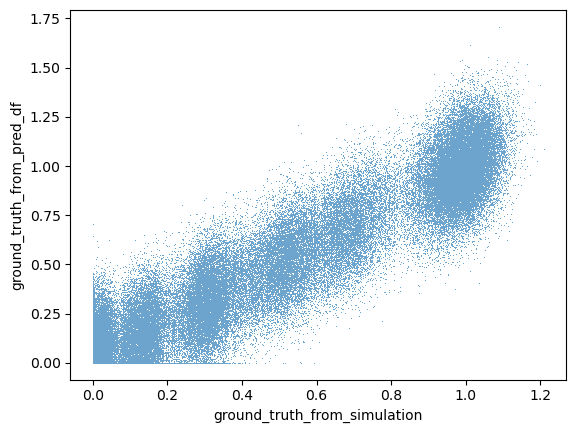

In [15]:
sns.scatterplot(data=outcome, x='ground_truth_from_simulation', y='ground_truth_from_pred_df', s=2, alpha=.2, marker='.')

In [16]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_timepoints']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_timepoints
0,Node_0,0.0,0.134606,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.022225,16
1,Node_1,0.0,0.741639,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.557310,16
2,Node_2,0.0,0.124709,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.080057,16
3,Node_3,0.0,0.955923,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.702816,16
4,Node_4,0.0,0.318532,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.057769,16
...,...,...,...,...,...,...,...,...,...
2519995,Node_45,1.0,1.003480,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.925542,21
2519996,Node_46,1.0,0.394155,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.321352,21
2519997,Node_47,1.0,0.190476,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.138196,21
2519998,Node_48,1.0,0.806056,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.833160,21


In [17]:
import string
genes_to_letter_map = {}
i = 0
for genes in outcome['modelled_genes'].unique():
    if genes is None:
        continue
    genes_to_letter_map[genes] = string.ascii_uppercase[i]
    i += 1
genes_to_letter_map

{"['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Node_12', 'Node_7', 'Node_25', 'Node_17', 'Node_35', 'Node_37', 'Node_43', 'Node_45', 'Node_47', 'Node_48']": 'A',
 "['Node_9', 'Node_18', 'Node_14', 'Node_21', 'Node_36', 'Node_40', 'Node_41']": 'B',
 "['Node_13', 'Node_0', 'Node_24', 'Node_5', 'Node_4', 'Node_28', 'Node_29', 'Node_19']": 'C',
 "['Node_30', 'Node_39', 'Node_10', 'Node_22', 'Node_26', 'Node_32', 'Node_33', 'Node_49']": 'D',
 "['Node_11', 'Node_1', 'Node_8', 'Node_31', 'Node_15', 'Node_16', 'Node_20', 'Node_38', 'Node_27', 'Node_34', 'Node_42', 'Node_44', 'Node_46']": 'E'}

In [18]:
outcome['model_name_long'] = outcome['model_name'] + ' ' + outcome['modelled_genes'].map(genes_to_letter_map).fillna('')
outcome['model_name_long'].nunique()

6

In [19]:
outcome['model_name_long'].unique().tolist()

['MLP ',
 'HybridModel A',
 'HybridModel B',
 'HybridModel C',
 'HybridModel D',
 'HybridModel E']

In [20]:
outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_timepoints,model_name_long
0,Node_0,0.0,0.134606,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.022225,16,MLP
1,Node_1,0.0,0.741639,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.557310,16,MLP
2,Node_2,0.0,0.124709,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.080057,16,MLP
3,Node_3,0.0,0.955923,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.702816,16,MLP
4,Node_4,0.0,0.318532,KO: Node_6. Env: None,fef5b5fe33a94235b770dace42b530e9,MLP,None,0.057769,16,MLP
...,...,...,...,...,...,...,...,...,...,...
2519995,Node_45,1.0,1.003480,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.925542,21,MLP
2519996,Node_46,1.0,0.394155,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.321352,21,MLP
2519997,Node_47,1.0,0.190476,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.138196,21,MLP
2519998,Node_48,1.0,0.806056,KO: Node_5. Env: None,e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.833160,21,MLP


In [21]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [23]:
from copy import deepcopy
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
        lambda row: lookup[(
            row['condition'],
            row['modelled_genes'] if row['modelled_genes'] is not None else None
        )],
        axis=1
    )
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [24]:
double_ko_df

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_timepoints,model_name_long
30400,Node_0,0.0,0.043417,"KO: Node_2, Node_35. Env: None",fef5b5fe33a94235b770dace42b530e9,MLP,None,0.102054,16,MLP
30401,Node_1,0.0,0.252418,"KO: Node_2, Node_35. Env: None",fef5b5fe33a94235b770dace42b530e9,MLP,None,0.520959,16,MLP
30402,Node_2,0.0,0.579040,"KO: Node_2, Node_35. Env: None",fef5b5fe33a94235b770dace42b530e9,MLP,None,0.628458,16,MLP
30403,Node_3,0.0,0.497529,"KO: Node_2, Node_35. Env: None",fef5b5fe33a94235b770dace42b530e9,MLP,None,0.398028,16,MLP
30404,Node_4,0.0,0.141590,"KO: Node_2, Node_35. Env: None",fef5b5fe33a94235b770dace42b530e9,MLP,None,0.271006,16,MLP
...,...,...,...,...,...,...,...,...,...,...
2507395,Node_45,1.0,0.985998,"KO: Node_7, Node_35. Env: None",e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,1.096496,21,MLP
2507396,Node_46,1.0,0.353063,"KO: Node_7, Node_35. Env: None",e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.310380,21,MLP
2507397,Node_47,1.0,0.186373,"KO: Node_7, Node_35. Env: None",e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.119164,21,MLP
2507398,Node_48,1.0,0.807091,"KO: Node_7, Node_35. Env: None",e467ba40a67a4f82be8ea111bb0ff48f,MLP,None,0.939778,21,MLP


In [25]:
from sklearn.metrics import mean_squared_error
import re

groupby_list = [
    'model_name', 
    'time',
    # 'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'nr_timepoints'
]
mse_df_long_model_name = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

mse_df_long_model_name['nr_timepoints'] = mse_df_long_model_name['nr_timepoints'].astype(int)
import matplotlib.colors as mcolors

# hybrid_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' in n]
# mlp_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' not in n]

# hybrid_colours = sns.blend_palette(["#f5a623", "#d45f00"], n_colors=len(hybrid_names))
# mlp_colours = sns.blend_palette(["#4a90d9", "#003f7f"], n_colors=len(mlp_names))

# palette = {name: colour for name, colour in zip(hybrid_names, hybrid_colours)}
# palette.update({name: colour for name, colour in zip(mlp_names, mlp_colours)})
# palette = {name: mcolors.to_hex(colour) for name, colour in palette.items()}

# mse_df_long_model_name


In [26]:
mse_df_long_model_name.nr_timepoints.value_counts()

nr_timepoints
21    105000
11    105000
16    105000
6     105000
9     105000
Name: count, dtype: int64

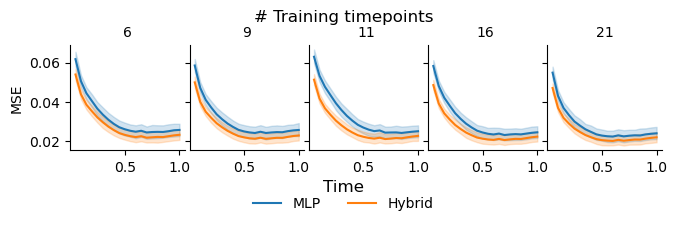

In [49]:
ignore_0 = mse_df_long_model_name[mse_df_long_model_name['time'] > 0].copy()
ignore_0 = ignore_0.rename(columns={'nr_timepoints': '# Training timepoints'})
ignore_0['model_name'] = ignore_0['model_name'].replace({'HybridModel': 'Hybrid'})

g = sns.relplot(data=ignore_0,
                x='time', y=DfColumnNames.MSE_COL,
                col='# Training timepoints', hue='model_name',
                kind='line', hue_order=['MLP', 'Hybrid'], estimator='mean')

g.set_titles(col_template="{col_name}")
g.set_axis_labels("", "MSE")

fig = g.figure
fig.set_size_inches(6.50, 2.2)                  
fig.subplots_adjust(bottom=0.32, top=0.80,
                    left=0.08, right=0.99)      

fig.supxlabel("Time", y=0.12)                   
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, -0.01),
                ncol=2, title=None, frameon=False)
fig.suptitle("# Training timepoints", y=0.96)

g.savefig("mse_over_time_sparser_timepoints_hybrids_together.pdf")   

Text(0.5, 0.01, 'time')

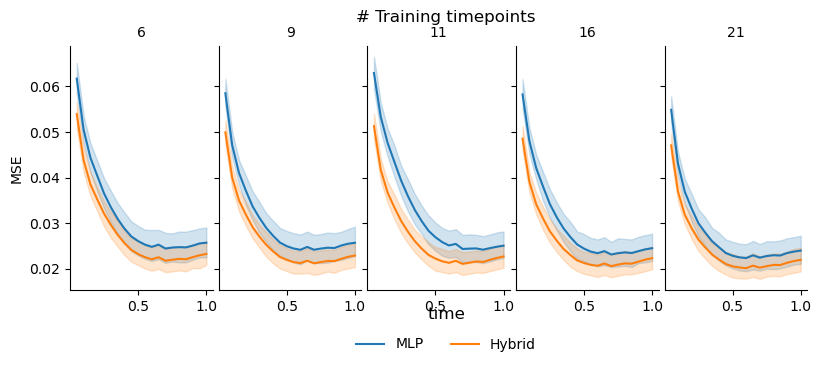

In [43]:
ignore_0 = mse_df_long_model_name[mse_df_long_model_name['time'] > 0]
ignore_0 = ignore_0.rename(columns={'nr_timepoints': '# Training timepoints'})
ignore_0['model_name'] = ignore_0['model_name'].replace({'HybridModel': 'Hybrid'})

g = sns.relplot(data=ignore_0, 
            x='time', y=DfColumnNames.MSE_COL,
             col='# Training timepoints', hue='model_name', # height=3, aspect=.7, 
             kind='line', hue_order=['MLP', 'Hybrid'], estimator='mean')

# Only the number in each column title
g.set_titles(col_template="{col_name}")
g.figure.set_size_inches(8,3)

# Legend below the subplots, no title
sns.move_legend(g, "upper center", bbox_to_anchor=(0.5, 0),
                ncol=2, title=None, frameon=False)

# One shared title on top of everything
g.figure.suptitle("# Training timepoints", y=1.05)

g.set_axis_labels("", "MSE")
g.figure.supxlabel("time") #, y=0.1)

# g.set(yscale='log')

# g.savefig("mse_over_time_sparser_timepoints_hybrids_together.pdf", dpi=600, bbox_inches='tight')

In [ ]:
g = sns.displot(data=mse_df_long_model_name, col='nr_timepoints', col_order=[6, 11, 21], x='MSE', hue='model_name_long', palette=palette, kind='ecdf', log_scale=(True), height=3)

for ax in g.axes.flat:
    lines = ax.get_lines()
    for line in lines:
        if mcolors.to_hex(line.get_color()) in [palette[name] for name in mlp_names]:
            line.set_zorder(10)
# g.savefig("noise_level_ecdf.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
from sklearn.metrics import mean_squared_error
import re

groupby_list = [
    'model_name_long', 
    'modelled_genes',
    'time',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'nr_timepoints'
]
mse_df_long_model_name = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

mse_df_long_model_name['nr_timepoints'] = mse_df_long_model_name['nr_timepoints'].astype(int)
import matplotlib.colors as mcolors

hybrid_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' in n]
mlp_names = [n for n in mse_df_long_model_name['model_name_long'].unique() if 'HybridModel' not in n]

hybrid_colours = sns.blend_palette(["#f5a623", "#d45f00"], n_colors=len(hybrid_names))
mlp_colours = sns.blend_palette(["#4a90d9", "#003f7f"], n_colors=len(mlp_names))

palette = {name: colour for name, colour in zip(hybrid_names, hybrid_colours)}
palette.update({name: colour for name, colour in zip(mlp_names, mlp_colours)})
palette = {name: mcolors.to_hex(colour) for name, colour in palette.items()}

mse_df_long_model_name


In [ ]:
ignore_0 = mse_df_long_model_name[mse_df_long_model_name['time'] > 0]
ignore_0 = ignore_0.rename(columns={'nr_timepoints': '# Training timepoints'})

In [ ]:
g = sns.relplot(data=ignore_0, 
            x='time', y=DfColumnNames.MSE_COL,
             col='# Training timepoints', hue='model_name_long', style='model_name_long', palette=palette, height=3, aspect=1, 
             kind='line')
# g.set(yscale='log')

# g.savefig("mse_over_time_sparser_timepoints.pdf", dpi=600, bbox_inches='tight')

Cells below only work when groupby was called with `model_name`

In [ ]:
mlp_mse = mse_df_long_model_name[mse_df_long_model_name['model_name'] == 'MLP'][['gene', 'condition', 'nr_timepoints', 'MSE', 'time_point_phase']].rename(columns={'MSE': 'mlp_mse'})
hybrid_mse = mse_df_long_model_name[mse_df_long_model_name['model_name'] == 'HybridModel'][['gene', 'condition', 'nr_timepoints', 'MSE', 'modelled_genes', 'time_point_phase']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mlp_mse, on=['gene', 'condition', 'nr_timepoints', 'time_point_phase'])
paired = annotate_kos_in_df(paired)

In [ ]:
paired = paired[paired['gene_in_mm'] == False]

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='nr_timepoints',  row='time_point_phase', hue='ko_in_mm',
                  alpha=.75, s=5, col_order=natsorted(paired['nr_timepoints'].unique()), height=3, aspect=1,
                )
# g.figure.set_size_inches(9, 3) 

g.set(xscale='log', yscale='log')

# from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# # ticks = [1e-4, 1e-3, 1e-2, 1e-1, 1e0]
# ticks = [1e-4, 1e-2, 1e0]

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8, zorder=0)
#     ax.set_xticks(ticks)
#     ax.set_yticks(ticks)
#     ax.xaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
#     ax.yaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
#     ax.plot([0, 1], [0, 1], 'k--', alpha=.5, zorder=0)
#     for collection in ax.collections:
#         collection.set_rasterized(True)


# for handle in g.legend.legend_handles:
#     try:
#         handle.set_markersize(5)
#     except AttributeError:
#         pass

# for text in g._margin_titles_texts:
#     text.set_visible(False)